In [1]:
# import knihoven
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from uncertainties import ufloat as uf
from uncertainties import unumpy as unp
from pathlib import Path

# path config
downloads_dir = Path.home() / 'Downloads'
# ujistime se, ze slozka existuje (kdyby nahodou ne)
downloads_dir.mkdir(parents=True, exist_ok=True)
# output_path = downloads_dir / 'muj_graf.png'

In [2]:
# definice funkci

# nejistota typu B u cteni z nejmensiho dilku
def unc_B_cteni(a):
    '''
    Nejistota typu B pro napr pravitko
    data : float
        nejmensi dilek
    return : float
        nejistota typu B
    '''
    u_B = a/(3**0.5)
    return u_B

# nejistota typu A 
def unc_A(data):
    '''
    Výpočet nejistoty typu A
    data : list nebo numpy array
         měření
    return : float
        nejistota typu A
    '''
    data = np.array(data)
    n = len(data)

    s = np.std(data, ddof=1)
    u_A = s / np.sqrt(n)
    
    return u_A

In [3]:
# nacteni google tabulek
sheet_id = '1WguDcMu3y95ozOn7a2cBLHqNAV9YbfoBmDYihw6zr6o'
gid = '0'
url = f'https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}'

df_hranol = pd.read_csv(url)
df_hranol.dropna()

,ψ₁ – stupně,ψ₁ – minuty,ψ₁ – vteřiny,ψ₂ – stupně,ψ₂ – minuty,ψ₂ – vteřiny


In [4]:
# lamavy uhel

psi1_df = df_hranol['ψ₁ – stupně'] + df_hranol['ψ₁ – minuty']/60 + df_hranol['ψ₁ – vteřiny']/3600
psi1 = psi1_df.to_numpy(dtype=float)

psi2_df = df_hranol['ψ₂ – stupně'] + df_hranol['ψ₂ – minuty']/60 + df_hranol['ψ₂ – vteřiny']/3600
psi2 = psi2_df.to_numpy(dtype=float)

omega = (180 - (psi1 - psi2))*np.pi/180
omega = uf(np.mean(omega), unc_A(omega))
omega_pokus = 59*np.pi/180

/home/fildapanko/Dokumenty/vs_code/praktikum/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/fildapanko/Dokumenty/vs_code/praktikum/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/fildapanko/Dokumenty/vs_code/praktikum/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/fildapanko/Dokumenty/vs_code/praktikum/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home/fildapanko/Dokumenty/vs_code/praktikum/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in scalar 

In [5]:
# nacteni google tabulek
sheet_id = '1WguDcMu3y95ozOn7a2cBLHqNAV9YbfoBmDYihw6zr6o'
gid = '37383797'
url = f'https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}'

df_deviace = pd.read_csv(url)
df_deviace

,Čára,Barva,λ [nm],φ₁ – stupně,φ₁ – minuty,φ₁ – vteřiny,φ₂ – stupně,φ₂ – minuty,φ₂ – vteřiny
0,1,Fialová,404.7,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Fialová,407.8,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Modrá,435.8,NaN,NaN,NaN,NaN,NaN,NaN
3,4,Modrozelená,491.6,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Zelená,546.1,NaN,NaN,NaN,NaN,NaN,NaN
5,6,Žlutá,576.9,NaN,NaN,NaN,NaN,NaN,NaN
6,7,Žlutá,579.1,NaN,NaN,NaN,NaN,NaN,NaN
7,8,Červená,623.4,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# deviace

phi1_df = df_deviace['φ₁ – stupně'] + df_deviace['φ₁ – minuty']/60 + df_deviace['φ₁ – vteřiny']/3600
phi1 = phi1_df.to_numpy(dtype=float)

phi2_df = df_deviace['φ₂ – stupně'] + df_deviace['φ₂ – minuty']/60 + df_deviace['φ₂ – vteřiny']/3600
phi2 = phi2_df.to_numpy(dtype=float)

delta_min = (phi1 - phi2)/2
delta_min_test = np.array([66, 66, 67, 69, 71, 74])*np.pi/180

# index lomu

#n = np.sin((delta_min+omega)/2)/np.sin(omega/2)
n_pokus = np.sin((delta_min_test+omega_pokus)/2)/np.sin(omega_pokus/2)
n_pokus

array([1.8013168 , 1.8013168 , 1.80943114, 1.82524582, 1.84050452,
       1.86233996])

/tmp/ipykernel_37301/4153434992.py:12: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(cauchy, vln_delka_test, n_pokus, p0)


1.7519997213836944 17532.954275186956 1.0
inf inf inf


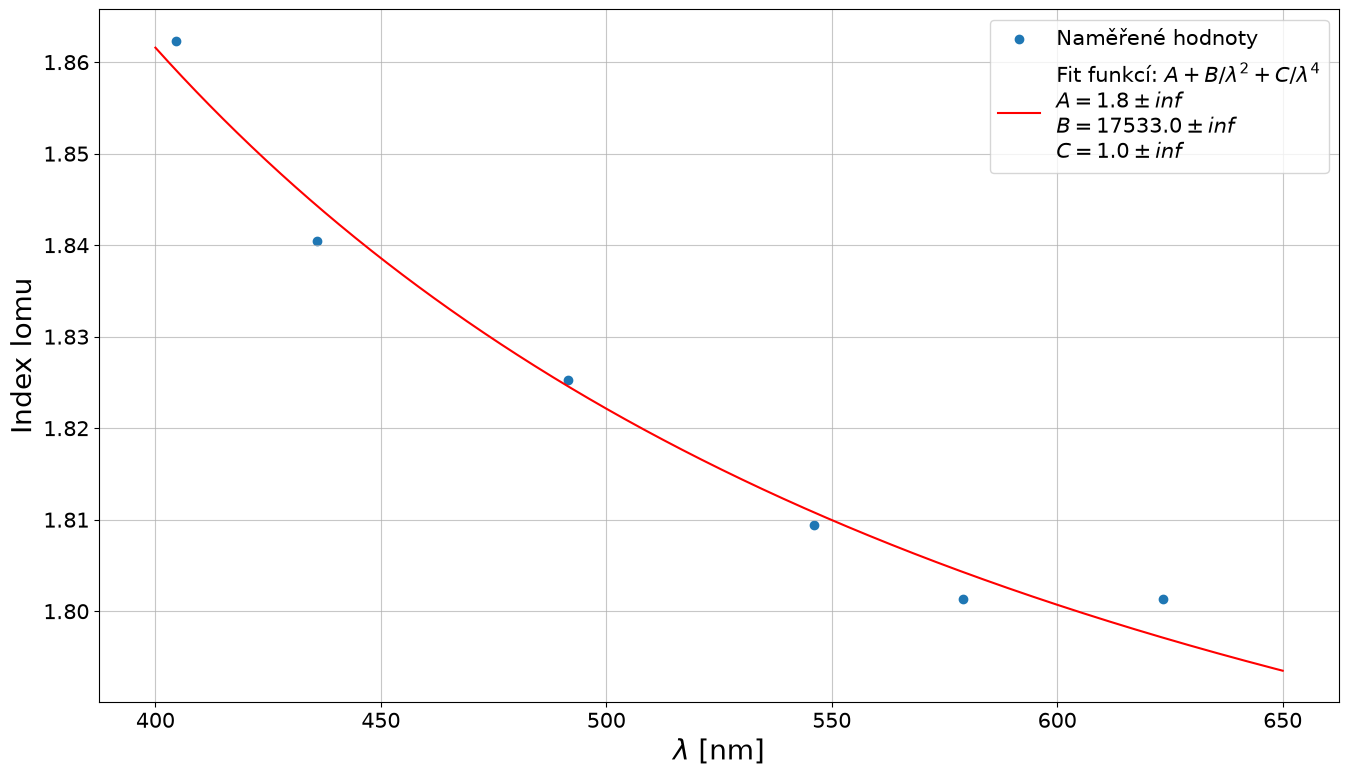

In [7]:
# cauchy fit
vln_delka = df_deviace['λ [nm]']
vln_delka_lispace = np.linspace(400, 650, 1000)

vln_delka_test = np.array([623.4, 579.1, 546.1, 491.6 , 435.8, 404.6 ])

def cauchy(vln_delka, A, B, C):
    x = 1/(vln_delka**2)
    return A + B*x + C*x**2

p0 = [2, 17000, 1]
popt, pcov = curve_fit(cauchy, vln_delka_test, n_pokus, p0)
A, B, C = popt
unc_A, unc_B, unc_C = np.sqrt(np.diag(pcov))
print(A, B, C)
print(unc_A, unc_B, unc_C)
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_ylabel(r'Index lomu', fontsize=20)
ax.set_xlabel(r'$\lambda$ [nm]', fontsize=20)
ax.scatter(vln_delka_test, n_pokus, label='Naměřené hodnoty')
ax.plot(vln_delka_lispace, cauchy(vln_delka_lispace, *popt), color='red', linestyle='-',
    label=r'Fit funkcí: $A + B/\lambda^2 + C/\lambda^4$''\n'
    fr'$A = {A:.1f} \pm {unc_A:.1f}$''\n'
    fr'$B = {B:.1f} \pm {unc_B:.1f}$''\n'
    fr'$C = {C:.1f} \pm {unc_C:.1f}$')
ax.tick_params(labelsize=15)
ax.grid(True, alpha=0.7)
ax.legend(fontsize=15)
plt.savefig(downloads_dir / 'cauchy.pdf', dpi=300, bbox_inches='tight')